## Tarea Random Forest y Árbol de Decisión
### Materia: Laboratorio de Aprendizaje Estádistico 
### Profesor: Antonio Manguart Paez
### Alumna: Maria Fernanda Gómez Flores


## Preparación de datos


In [11]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score
import numpy as np


In [12]:
df = pd.read_csv('../Data/Hitters_examen.csv')
df.head()


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


In [13]:
df = df.dropna()


In [14]:
df = pd.get_dummies(df)


In [15]:
X = df.copy()
del X['Salary']
y = df['Salary']


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)


## Árbol de decisión


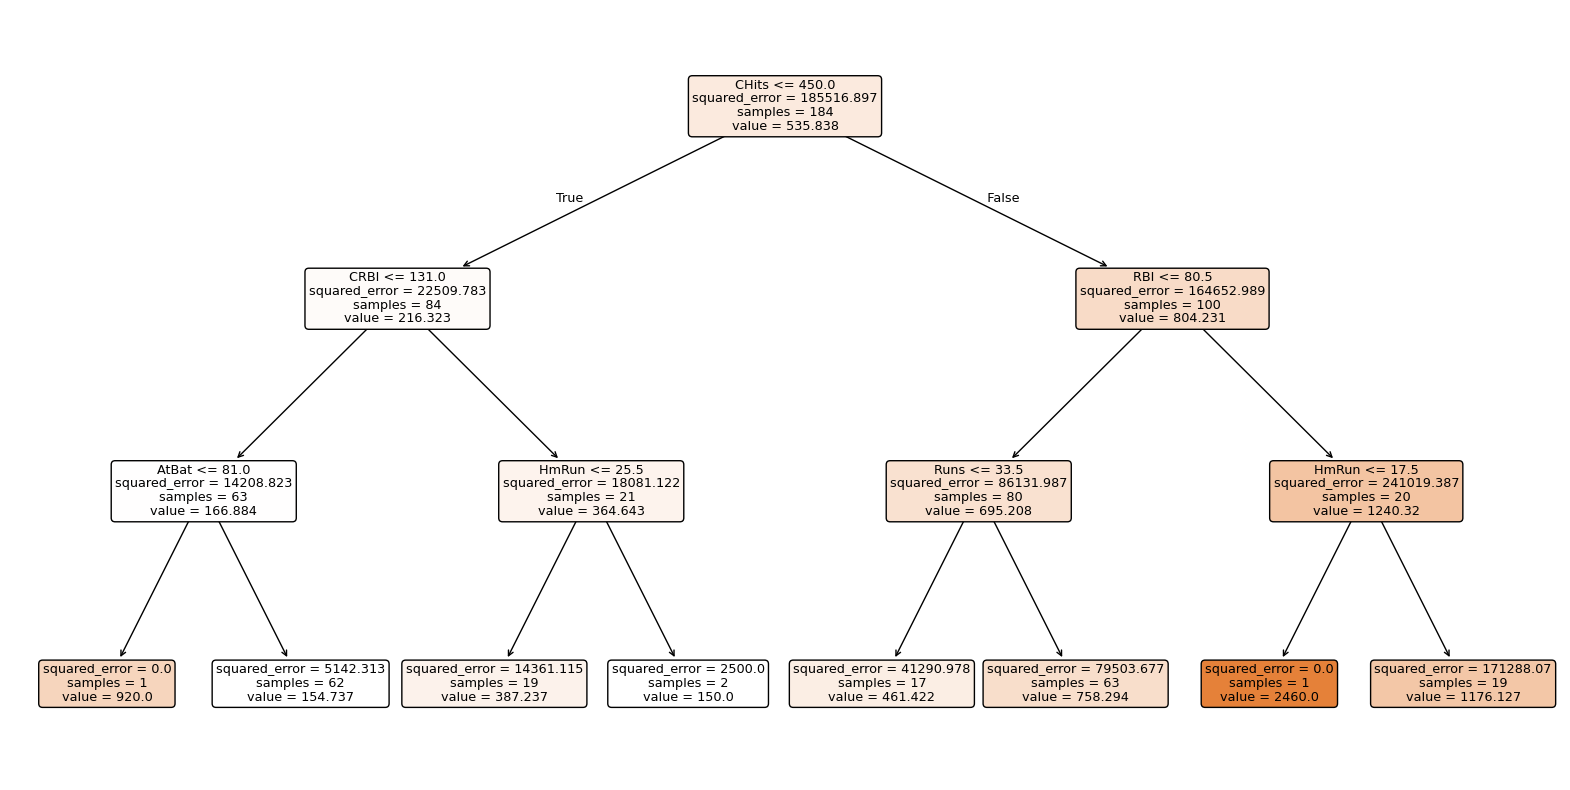

In [17]:
# Train model    
model = DecisionTreeRegressor(max_depth=3, random_state=42, 
                                  max_features='sqrt')
model.fit(X_train, y_train)

plt.figure(figsize=(20, 10)) 
plot_tree(model, feature_names=X.keys(), filled=True, rounded=True)
plt.show()


In [18]:
predicciones = model.predict(X_test)

r2_arbol = r2_score(
    y_pred=predicciones,
    y_true=y_test
)

r2_arbol


0.28736174461063035

## Random Forest


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline


In [20]:
pipeline = Pipeline([
    ('rf', RandomForestRegressor(n_estimators=300))
])

params = {
    'rf__max_depth': [6, 10, 12, 15, 20],
    'rf__max_features' :['sqrt', 'log2', 10]
}

grid_rf = GridSearchCV(estimator=pipeline, cv=5, n_jobs=-1, param_grid=params, scoring='r2')
grid_rf.fit(X_train, y_train)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('rf',
                                        RandomForestRegressor(n_estimators=300))]),
             n_jobs=-1,
             param_grid={'rf__max_depth': [6, 10, 12, 15, 20],
                         'rf__max_features': ['sqrt', 'log2', 10]},
             scoring='r2')

In [21]:
grid_rf.best_params_


{'rf__max_depth': 6, 'rf__max_features': 'log2'}

In [22]:
best_forest = grid_rf.best_estimator_.named_steps['rf']


In [23]:
predicciones = best_forest.predict(X_test)


In [24]:
r2_rf = r2_score(
    y_pred=predicciones,
    y_true=y_test
)

r2_rf


0.49790896193947665

## Comparación


In [25]:
comparacion = pd.DataFrame({
    'Modelo': [
        'Arbol de decision',
        'Random Forest'
    ],
    'R2 prueba': [
        r2_arbol,
        r2_rf
    ]
})

comparacion.sort_values('R2 prueba', ascending=False).round(3)


,Modelo,R2 prueba
1,Random Forest,0.498
0,Arbol de decision,0.287


### 1. ¿Qué puedes concluir?

El Random Forest funciono mejor que el arbol de decision porque obtuvo un R2 de 0.498 mientras que el arbol obtuvo 0.287

### 2. ¿Cuál gana?

Gana Random Forest

### 3. ¿Cuál tiene mejor R2?

Random Forest con un R2 de 0.498 mientras que el arbol tuvo 0.287


## 4. Explica el árbol


El arbol va haciendo divisiones con las variables y va separando a los jugadores en grupos con salarios diferentes hasta llegar a las hojas donde sale la prediccion de Salary


## 5. Variables más importantes del Random Forest


In [26]:
importancia_variables = pd.DataFrame({
    'variable': X_train.keys(),
    'importancia': best_forest.feature_importances_
})
importancia_variables


,variable,importancia
0,AtBat,0.044466
1,Hits,0.056650
2,HmRun,0.031259
3,Runs,0.041024
4,RBI,0.055449
5,Walks,0.040059
6,Years,0.044999
7,CAtBat,0.119844
8,CHits,0.111827
9,CHmRun,0.072161


In [27]:
importancia_variables.sort_values('importancia', ascending=False)


,variable,importancia
11,CRBI,0.120063
7,CAtBat,0.119844
8,CHits,0.111827
10,CRuns,0.107110
12,CWalks,0.074298
9,CHmRun,0.072161
1,Hits,0.056650
4,RBI,0.055449
6,Years,0.044999
0,AtBat,0.044466


Las variables mas importantes fueron CRBI CAtBat CHits CRuns y CWalks
